<a href="https://colab.research.google.com/github/chhote2827-ctrl/Netflix-Movies-and-TV-Shows-Data-Analysis/blob/main/Netflix_Titles.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

import the Netflix_Titles csv file in google.colab

In [2]:
# import drive
from google.colab import drive

# import pandas library
import pandas as pd

# connect to drive
drive.mount('/content/drive')
file_path = ('/content/drive/MyDrive/Project Data analysh/netflix_titles.csv')

# create the dataframe and read csv file
df = pd.read_csv(file_path)
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


 Netflix_Titles csv file full Info()

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


 Netflix_Titles csv file Describe

In [4]:
df.describe()

,release_year
count,8807.000000
mean,2014.180198
std,8.819312
min,1925.000000
25%,2013.000000
50%,2017.000000
75%,2019.000000
max,2021.000000


check the missing or null values in  Netflix_Titles csv file

In [5]:
df.isnull().sum()

,0
show_id,0
type,0
title,0
director,2634
cast,825
country,831
date_added,10
release_year,0
rating,4
duration,3


replace the column (director,cast,country) null values in 'unknown'

In [8]:
# Original small letter columns ko hi overwrite karein
df['director'] = df['director'].fillna('Unknown')
df['cast'] = df['cast'].fillna('Unknown')
df['country'] = df['country'].fillna('Unknown')

# Check karne ke liye specific columns ka head dekhein
df[['director', 'cast', 'country']].head()

,director,cast,country
0,Kirsten Johnson,Unknown,United States
1,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa
2,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown
3,Unknown,Unknown,Unknown
4,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India


drop the column in date_addede, rating, duration

In [12]:
# Teeno columns se null values wali rows drop karna
df = df.dropna(subset=['date_added', 'rating', 'duration'])

# check kiya ki missing values hai ya nahi
print(df[['date_added', 'rating', 'duration']].isnull().sum())

date_added    0
rating        0
duration      0
dtype: int64


duplicates values check karna

In [13]:
df.duplicated().sum()

np.int64(0)

features engineering
total count movies and TV shows with contribution percentage

In [14]:
# total counts with movies and tv shows
type_counts = df['type'].value_counts()
print("--- Total Counts ---")
print(type_counts)

# distribution in percentage form
print("\n--- Contribution Percentage (%) ---")
type_percentage = df['type'].value_counts(normalize=True) * 100
print(type_percentage.round(2))


--- Total Counts ---
type
Movie      6126
TV Show    2664
Name: count, dtype: int64

--- Contribution Percentage (%) ---
type
Movie      69.69
TV Show    30.31
Name: proportion, dtype: float64


count the country with percentage

In [15]:
# total counts with country
country_counts = df['country'].value_counts()
print("--- Total Counts ---")
print(country_counts)

# distribution in percentage form
print("\n--- Contribution Percentage (%) ---")
country_percentage = df['country'].value_counts(normalize=True) * 100
print(country_percentage.round(2))


--- Total Counts ---
country
United States                                             2809
India                                                      972
Unknown                                                    829
United Kingdom                                             418
Japan                                                      243
                                                          ... 
Germany, Canada, United States                               1
Denmark, United Kingdom, South Africa, Sweden, Belgium       1
Serbia, South Korea, Slovenia                                1
United Kingdom, Spain, Belgium                               1
South Africa, United States, Japan                           1
Name: count, Length: 749, dtype: int64

--- Contribution Percentage (%) ---
country
United States                                             31.96
India                                                     11.06
Unknown                                                    9.43
Un

Geographical Analysis

/tmp/ipykernel_10705/1659169700.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_countries.values, y=top_countries.index, palette='viridis')


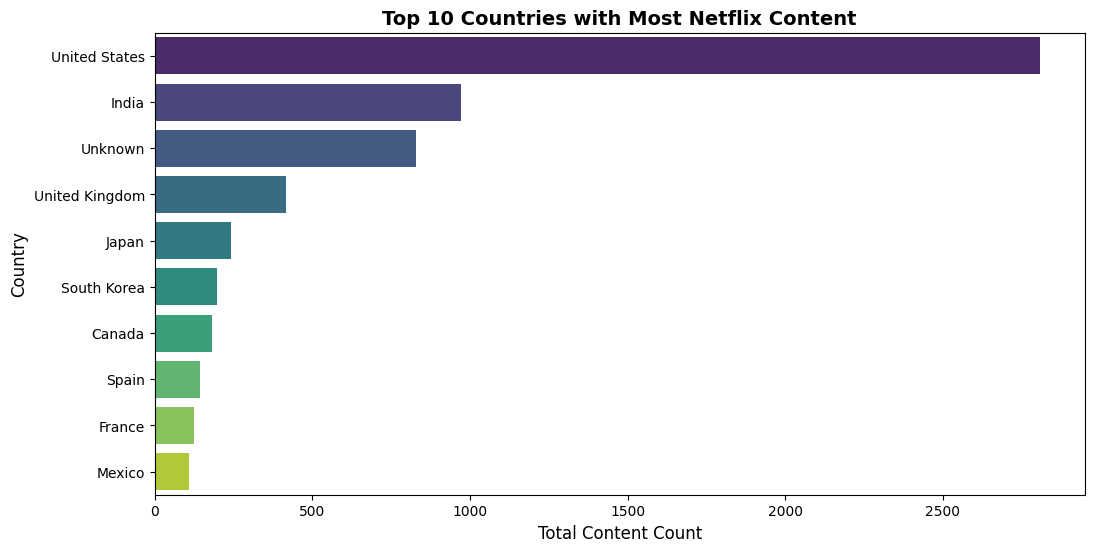

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

# Agar country column mein nulls hain to replace with unknown
df['country'] = df['country'].fillna('Unknown')

# Top 10 countries nikalna (Multiple countries ko split karne ke baad ya direct count)
top_countries = df['country'].value_counts().head(10)

# Plotting
plt.figure(figsize=(12, 6))
sns.barplot(x=top_countries.values, y=top_countries.index, palette='viridis')
plt.title('Top 10 Countries with Most Netflix Content', fontsize=14, fontweight='bold')
plt.xlabel('Total Content Count', fontsize=12)
plt.ylabel('Country', fontsize=12)
plt.show()

Temporal Trends

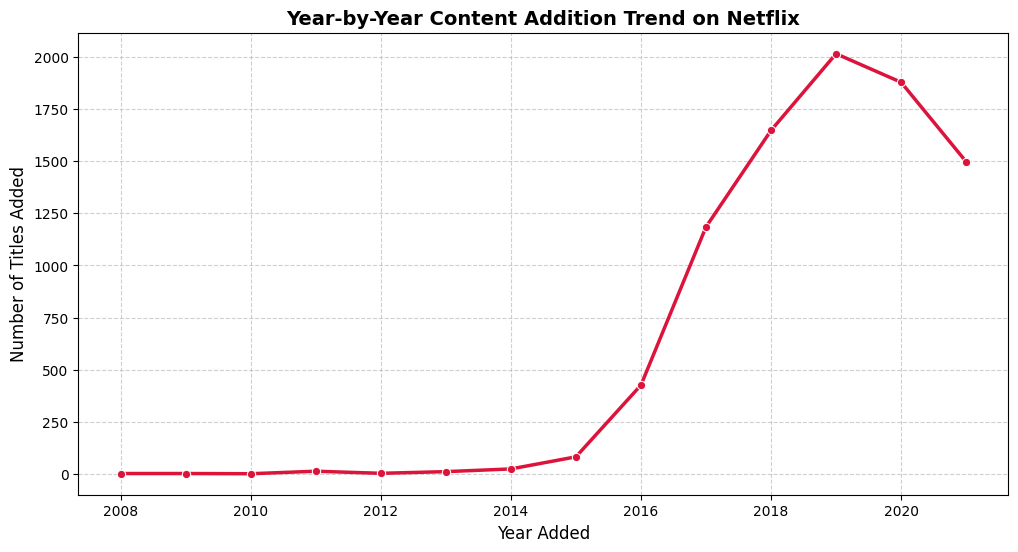

In [17]:
# Date added se year extract karna
df['year_added'] = pd.to_datetime(df['date_added'].str.strip(), errors='coerce').dt.year

# Saalo ke hisab se count
yearly_trend = df['year_added'].value_counts().sort_index()

# Plotting with line chart
plt.figure(figsize=(12, 6))
sns.lineplot(x=yearly_trend.index, y=yearly_trend.values, marker='o', color='crimson', linewidth=2.5)
plt.title('Year-by-Year Content Addition Trend on Netflix', fontsize=14, fontweight='bold')
plt.xlabel('Year Added', fontsize=12)
plt.ylabel('Number of Titles Added', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Content Ratings

/tmp/ipykernel_10705/981351029.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_ratings.index, y=top_ratings.values, palette='magma')


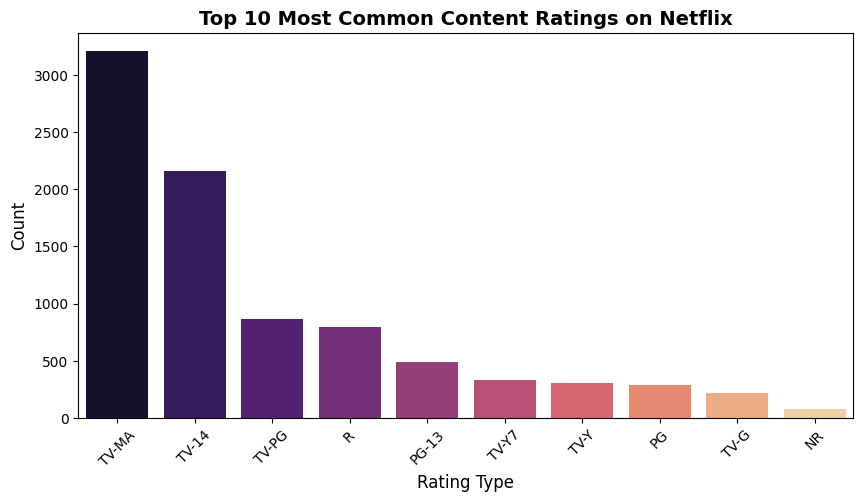

In [18]:
# Top 10 ratings count
top_ratings = df['rating'].value_counts().head(10)

# Plotting
plt.figure(figsize=(10, 5))
sns.barplot(x=top_ratings.index, y=top_ratings.values, palette='magma')
plt.title('Top 10 Most Common Content Ratings on Netflix', fontsize=14, fontweight='bold')
plt.xlabel('Rating Type', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=45)
plt.show()

Genre / Category Analysis

In [ ]:
# Genres column mein ek movie ke multiple genres comma-separated hain unhe split karke count karna
top_genres = df['listed_in'].str.split(', ').explode().value_counts().head(10)

# Plotting
plt.figure(figsize=(12, 6))
sns.barplot(x=top_genres.values, y=top_genres.index, palette='crest')
plt.title('Top 10 Genres on Netflix', fontsize=14, fontweight='bold')
plt.xlabel('Count', fontsize=12)
plt.ylabel('Genre', fontsize=12)
plt.show()

Duration Insights

<>:6: SyntaxWarning: invalid escape sequence '\d'
<>:6: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_10705/1909410715.py:6: SyntaxWarning: invalid escape sequence '\d'
  movies_df['duration_int'] = movies_df['duration'].str.extract('(\d+)').astype(float)


Movies ki Average Duration: 99.58 minutes


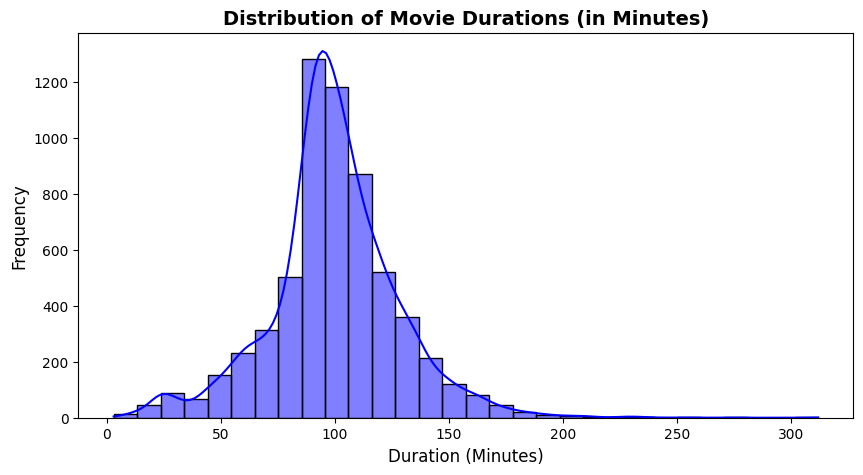

In [19]:
# Data ko Movies aur TV Shows mein divide karna
movies_df = df[df['type'] == 'Movie'].copy()
tv_shows_df = df[df['type'] == 'TV Show'].copy()

# Movies ke duration se 'min' hata kar integer mein convert karna (jaise '90 min' -> 90)
movies_df['duration_int'] = movies_df['duration'].str.extract('(\d+)').astype(float)

print(f"Movies ki Average Duration: {movies_df['duration_int'].mean():.2f} minutes")

# Plotting Movie Duration Distribution
plt.figure(figsize=(10, 5))
sns.histplot(movies_df['duration_int'].dropna(), bins=30, kde=True, color='blue')
plt.title('Distribution of Movie Durations (in Minutes)', fontsize=14, fontweight='bold')
plt.xlabel('Duration (Minutes)', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.show()

final dataset

In [20]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description,year_added
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Unknown,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm...",2021
1,s2,TV Show,Blood & Water,Unknown,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t...",2021
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",Unknown,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...,2021
3,s4,TV Show,Jailbirds New Orleans,Unknown,Unknown,Unknown,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo...",2021
4,s5,TV Show,Kota Factory,Unknown,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...,2021
